# 02 · Manifold — principal-curve trajectory

Sun's malignant manifold is **non-branching**: one connected component with an elongated
crescent shape, not a hub radiating to discrete subtypes and not two separable lobes (01
established a single connected component with no compartment to scope out). The correct
topology is therefore a **principal curve** (ElPiGraph, non-branching by construction) fit
on the *joint* embedding — **not** a re-embedding (an elongated compartment is honest 1-D
geometry; re-embedding an anisotropic strip fabricates folds). Unlike Kürten (which scoped
the curve to an embryonic sub-lobe), the curve here spans the **full** manifold (Bischoff
lung precedent). It is rooted at the gastrulation/somitogenesis-high tip (the developmental
origin), pseudotime flows to the neural-crest terminus, and the embedding is reoriented to
house style (low pseudotime left → high right). Deliverable: `manifold.h5ad`, `manifold.pdf`.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load processed manifold — full component (no compartment restriction)
We keep every cell on its *original joint embedding coordinates* — no re-embedding. 01
established one connected component with no discrete cycling lobe to scope out, so the
trajectory spans the full manifold.

manifold: 2337 cells on the joint embedding (full component)
UMAP strip aspect ratio (major/minor std): 2.71  (elongated -> 1-D geometry)


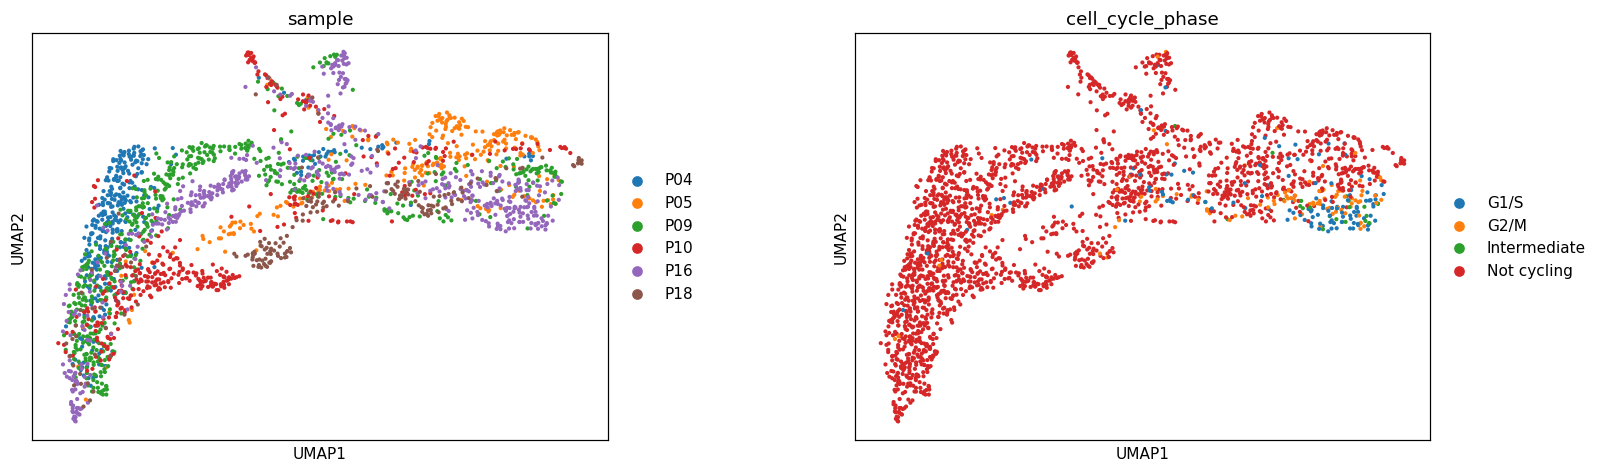

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
sub = adata.copy()
print('manifold:', sub.shape[0], 'cells on the joint embedding (full component)')
xy = sub.obsm['X_umap']
from numpy.linalg import svd
c = xy - xy.mean(0); u,s,vt = svd(c, full_matrices=False)
print(f'UMAP strip aspect ratio (major/minor std): {s[0]/s[1]:.2f}  (elongated -> 1-D geometry)')
fig = sc.pl.umap(sub, color=['sample','cell_cycle_phase'], size=30, wspace=.3, show=False)

### Fit the principal curve (ElPiGraph)
`Nodes/epg_lambda/epg_mu` were tuned to give a **fold-free** monotone backbone: a node
self-approach ratio > 1 (minimum distance between graph-non-adjacent nodes, in units of
median edge length) certifies the curve does not fold back on itself. `epg_mu=100` is
strong bending regularisation (ElPiGraph: `epg_lambda` penalises stretching, `epg_mu`
penalises bending), keeping the crescent a smooth arc rather than a sharp V that would
assign near-neighbour cells divergent pseudotime across an inflection. The topology
(2 tips, 0 forks) was confirmed stable across `Nodes` in {15,20,30}.

In [4]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3:
                dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks

with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print(f'curve: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'

curve: 2 tips, 0 forks | fold self-approach ratio = 2.97 (>1 = fold-free)


### Score embryonic modules and derive the root (data-driven)
The three developmental signatures (Gastrulation / Somitogenesis / Neural-crest) are scored
against the shared **union** control gene pool (`ctrl_as_ref=False`), then graph-smoothed to
read *geography* rather than single-cell dropout. The root is set to the curve tip where
Gast+pSom is highest and Crest lowest — the developmental origin (neural crest is a late
derivative).

In [5]:
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(sub.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src,lab in label.items():
    g = feat[src].loc[feat[src].isin(sub.var_names)]
    sc.tl.score_genes(sub, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
# graph-smooth for geography
A = (sub.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = sub.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): sub.obs[lab+'_sm'] = S[:,j]

Gast: 79/81 genes present
pSom: 94/98 genes present
Crest: 104/104 genes present


In [6]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for t in tps:
    m = np.isin(hard, np.where(D[t]<=3)[0])
    info[t] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {t}: Gast={info[t][0]:+.4f} pSom={info[t][1]:+.4f} Crest={info[t][2]:+.4f}')
root = int(max(tps, key=lambda t: info[t][0]+info[t][1]-info[t][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
print('gradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p = spearmanr(t, sub.obs[s]); print(f'  {s}: rho={rho:+.3f} p={p:.1e}')

tip 0: Gast=+0.0083 pSom=+0.0456 Crest=-0.0427
tip 2: Gast=-0.0544 pSom=+0.0592 Crest=+0.0009
derived root = tip 0 (Gast/pSom-high, Crest-low)
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho=-0.785 p=0.0e+00
  pSom_sm: rho=+0.253 p=1.5e-35
  Crest_sm: rho=+0.595 p=6.5e-224


### Fold check — render the fitted curve edges (Chen §4 lesson)
The self-approach ratio above certifies fold-freeness analytically; here we also *draw the
curve edges* over the cloud so the topology is verified visually, not judged blind on
signature↔pseudotime correlations (the failure mode where a W-folded curve passed its
correlation checks). This render is a diagnostic, not a deliverable.

curve-edge render: single monotone arc, no self-crossing -> fold-free (matches self-approach ratio)


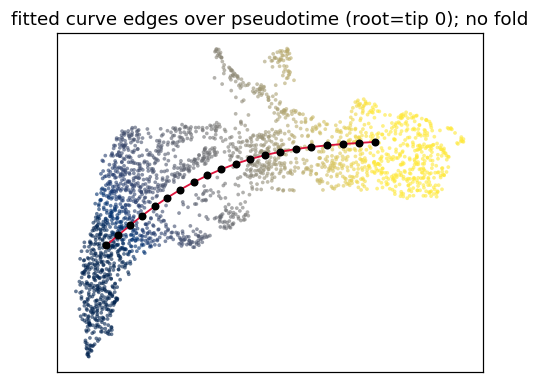

In [7]:
F = sub.uns['graph']['F'].T          # node coordinates in the fit space (X_umap)
Bc = np.asarray(sub.uns['graph']['B'])
fig, ax = plt.subplots(figsize=(5,4))
ax.scatter(sub.obsm['X_umap'][:,0], sub.obsm['X_umap'][:,1], s=6,
           c=sub.obs['t'], cmap='cividis', alpha=.6, lw=0)
ii,jj = np.where(np.triu(Bc>0))
for a,b in zip(ii,jj):
    ax.plot([F[a,0],F[b,0]],[F[a,1],F[b,1]], '-', color='crimson', lw=1.2)
ax.scatter(F[:,0],F[:,1], s=18, c='k', zorder=5)
rt = sub.uns['graph'].get('root', root)
ax.set_title(f'fitted curve edges over pseudotime (root=tip {root}); no fold'); ax.set_xticks([]); ax.set_yticks([])
print('curve-edge render: single monotone arc, no self-crossing -> fold-free (matches self-approach ratio)')

### Reorient to house style (pseudotime left → right)
Orient the linear-trajectory panel using only raw UMAP coordinates with a discrete axis flip
(no rotation/interpolation — those are brittle: an SVD basis can be a reflection and silently
flip an axis). *This dataset's* trajectory major axis is already near-horizontal in the raw
embedding (unlike Kürten, whose axis was near-vertical and needed an x↔y swap). We therefore
place the pseudotime axis on x and **derive the flip sign from the pseudotime itself**:
`sx = sign(corr(raw_x, t))`, giving `X_umap_lin = (sx·raw_x, raw_y)` — guaranteeing low
pseudotime on the left without assuming a sign. The same fixed transform (recorded in
`uns['orient_sx']`) is applied identically in every deliverable notebook.

In [8]:
xy = sub.obsm['X_umap'].copy(); t = sub.obs['t'].values
sx = 1.0 if np.corrcoef(xy[:,0], t)[0,1] > 0 else -1.0   # derive flip sign from pseudotime
xyr = np.column_stack([sx*xy[:,0], xy[:,1]])             # x on pseudotime axis, no rotation/swap
r = float(np.corrcoef(xyr[:,0], t)[0,1])
assert r > 0, f'orientation derivation failed (corr={r:+.2f})'
sub.obsm['X_umap_lin'] = xyr
sub.uns['orient_sx'] = sx
print(f'orientation: X_umap_lin = ({sx:+.0f}*raw_x, raw_y) [derived sign]; '
      f'corr(x_lin, pseudotime) = {r:+.2f} (low pt on left)')

orientation: X_umap_lin = (+1*raw_x, raw_y) [derived sign]; corr(x_lin, pseudotime) = +0.98 (low pt on left)


### Save manifold + trajectory figure (deliverable)

saved manifold.h5ad + manifold.pdf | cells: 2337


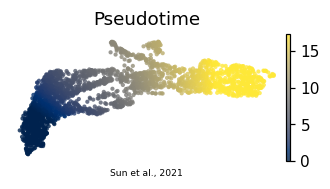

In [9]:
# sanitize non-serializable ElPiGraph uns entry (node positions kept; graph lives in uns['graph'])
if 'epg' in sub.uns:
    sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = sub.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Sun et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf | cells:', sub.n_obs)